In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import microimage

data_dir = "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat"
results_dir = "results"
db_path = "database.db"
exp = microimage.ExperimentManager(data_dir, results_dir, db_path)
exp.scan_data_directory(["*.czi"])

In [ ]:
# from prrt_clustering import correct_z_drift, detect_puncta, cluster_dbscan, pair_cluster, pair_puncta
import prrt_clustering as pclst
from pathlib import Path
from bioio import BioImage
import yaml


def process(data_path: Path, output_folder, parameters):
    """Process."""
    name = data_path.stem
    print(name)
    with open(output_folder / f"{name}_parameters.yaml", "w") as f:
        yaml.safe_dump(parameters, f)
    image = BioImage(data_path)
    data = image.xarray_dask_data.assign_coords({"C": parameters["channels"]})
    shift, stabilized = pclst.correct_z_drift(data)
    points = pclst.detect_puncta(stabilized[0], parameters["detection"])
    points, clusters = pclst.cluster_dbscan(points, **parameters["dbscan"])
    points, synapses = pclst.pair_cluster(
        points, ["PSD", "RIM"], **parameters["synapse"]
    )
    points, pairs = pclst.pair_puncta(points, ["A1", "PRRT"], **parameters["pairs"])
    points = pclst.associate_to_paired_cluster(points, **parameters["synapse"])
    points = pclst.compute_distances(points)
    g_stats = pclst.global_stats(points, **parameters["synapse"])
    s_stats = pclst.synapse_stats(points)
    s_stats.to_csv(output_folder / f"{name}_s_stats.csv")
    points.to_csv(output_folder / f"{name}_points.csv")
    with open(output_folder / f"{name}_g_stats.yaml", "w") as f:
        yaml.safe_dump(g_stats, f)


In [ ]:
data_path = Path(
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/"
)
parameters = {
    "channels": ["PRRT", "A1", "PSD", "RIM"],
    "detection": {
        "PRRT": {"scale_um": 0.4, "specificity": 6},
        "A1": {"scale_um": 0.3, "specificity": 6},
        "PSD": {"scale_um": 0.1, "specificity": 8},
        "RIM": {"scale_um": 0.1, "specificity": 6},
    },
    "dbscan": {"eps": 1.5, "min_samples": 3},
    "synapse": {"distance": 1},
    "pairs": {"distance": 0.5},
}

output_folder = Path("./results")
for filename in data_path.glob("**/*.czi"):
    process(filename, output_folder, parameters)


Experiment-360
Experiment-349
Experiment-358
Experiment-359
Experiment-362


Reload all results

In [ ]:
import pandas as pd

sst = pd.concat(
    [
        pd.read_csv(x, index_col=0).assign(file=x.stem)
        for x in output_folder.glob("*_s_stats.csv")
    ],
    ignore_index=True,
)
points = pd.concat(
    [
        pd.read_csv(x, index_col=0).assign(file=x.stem)
        for x in output_folder.glob("*_points.csv")
    ],
    ignore_index=True,
)


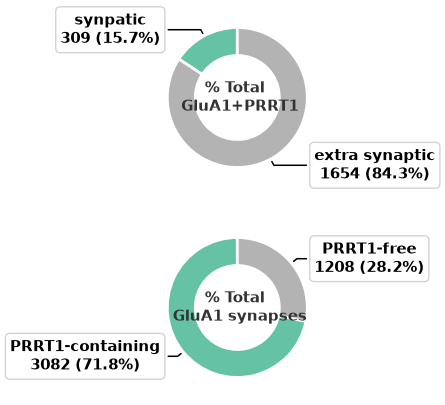

In [ ]:
from prrt_clustering.plot import make_the_bagel_plot
import matplotlib.pyplot as plt

gst = []
for x in output_folder.glob("*_g_stats.yaml"):
    with open(x, "r") as f:
        gst.append(yaml.safe_load(f))
        gst[-1]["file"] = x.stem
gst = pd.DataFrame.from_records(gst)


make_the_bagel_plot(gst.sum().to_dict(), sst)
plt.savefig(output_folder / "bagel.pdf")

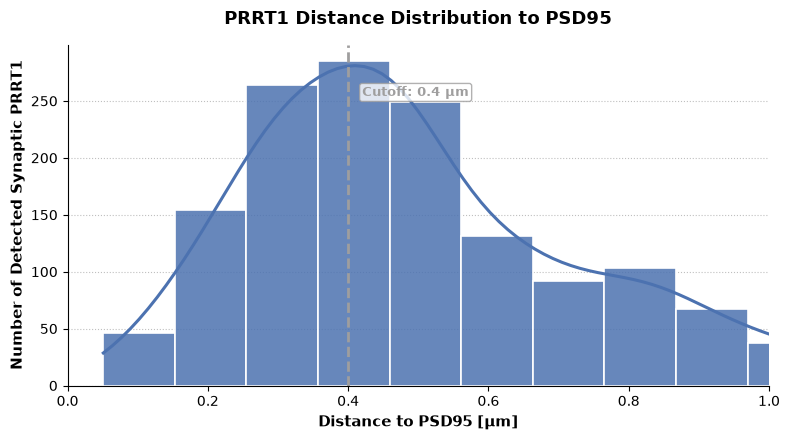

In [42]:
from prrt_clustering.plot import make_the_histogram_distance

make_the_histogram_distance(points)

In [52]:
gst.melt(id_vars="file")

,file,variable,value
0,Experiment-360_g_stats,Average distance of A1 to PSD,0.658343
1,Experiment-359_g_stats,Average distance of A1 to PSD,0.440410
2,Experiment-349_g_stats,Average distance of A1 to PSD,0.549328
3,Experiment-362_g_stats,Average distance of A1 to PSD,0.584371
4,Experiment-358_g_stats,Average distance of A1 to PSD,0.504711
...,...,...,...
185,Experiment-360_g_stats,poisson pvalue RIM:PSD,0.000000
186,Experiment-359_g_stats,poisson pvalue RIM:PSD,0.000000
187,Experiment-349_g_stats,poisson pvalue RIM:PSD,0.000000
188,Experiment-362_g_stats,poisson pvalue RIM:PSD,0.000000


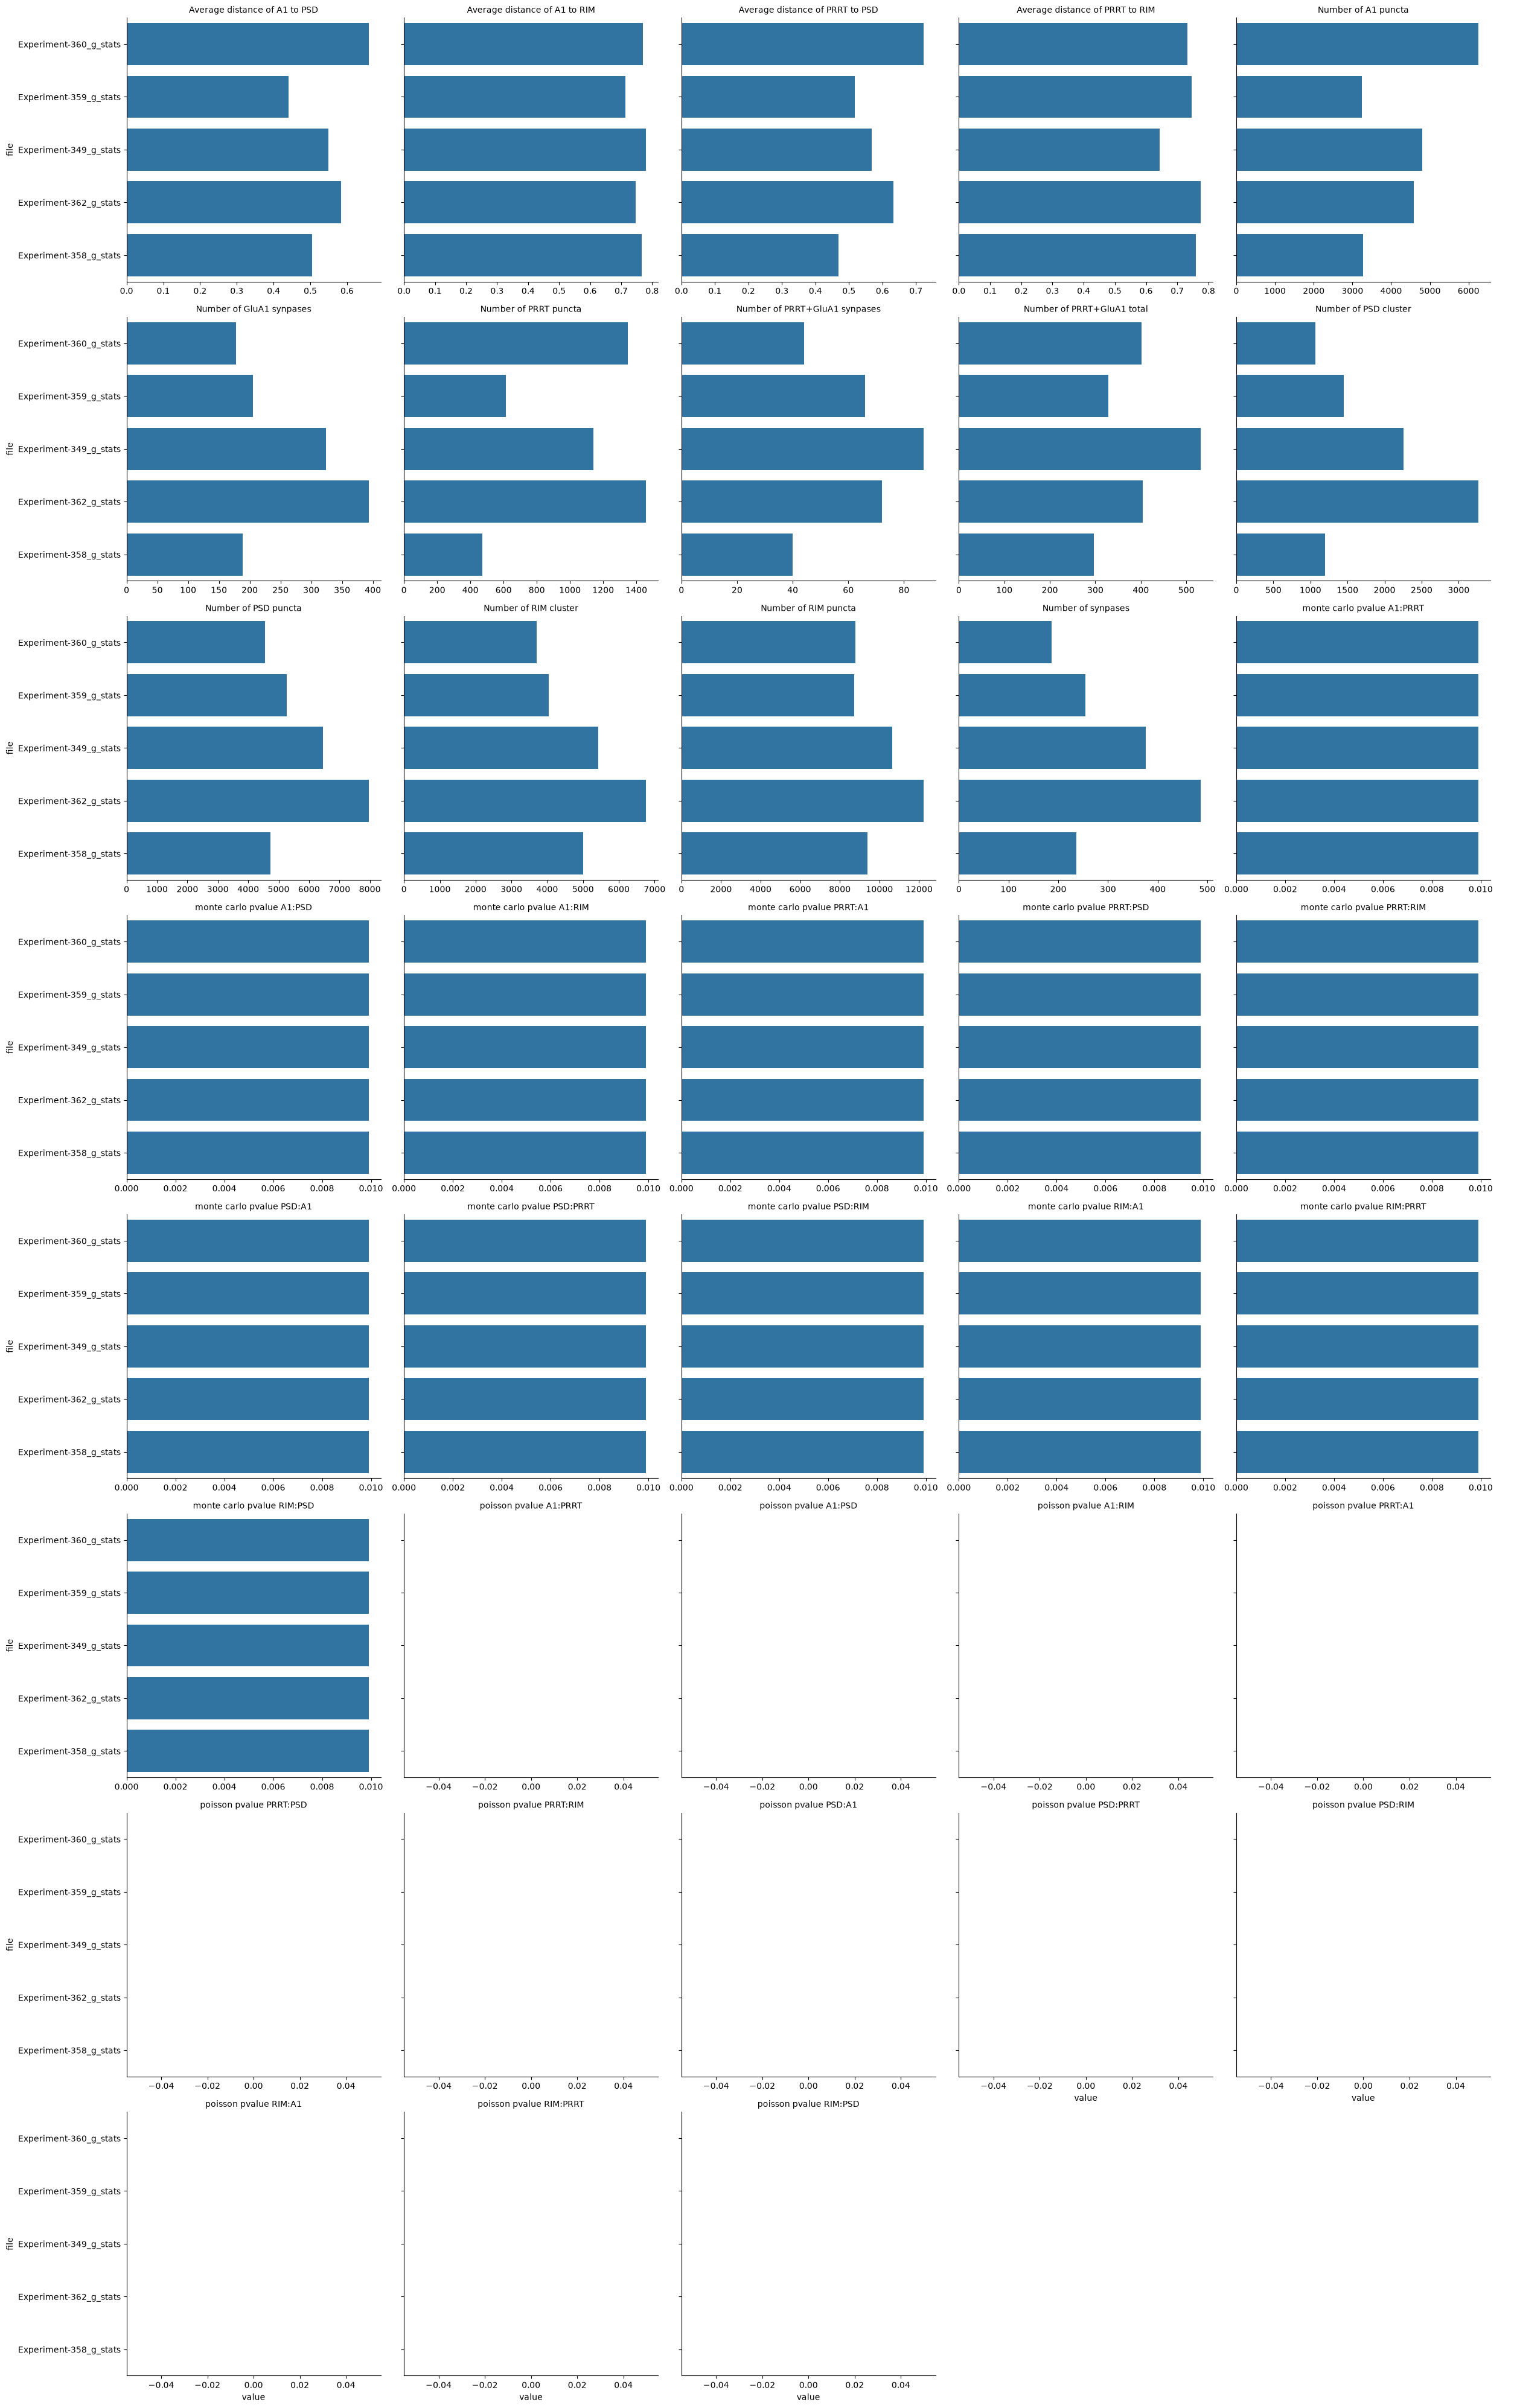

In [59]:
import seaborn as sns

sns.catplot(
    gst.melt(id_vars="file"),
    y="file",
    x="value",
    col="variable",
    col_wrap=5,
    kind="bar",
    sharex=False,
).set_titles("{col_name}")